## RetailIQ -- Exploratory Data Analysis
### Stage 3
##### This notebook explores the processed RetailIQ dataset
##### to identify business trends, patterns, and insights.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the processed dataset created during Stage 2.
data_path = "../data/processed/retailiq_order_item_data.csv"

retailiq = pd.read_csv(
    data_path,
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

# Display the size of the analytical dataset.
print(f"Rows: {len(retailiq):,}")
print(f"Columns: {len(retailiq.columns)}")

Rows: 112,650
Columns: 41


In [2]:
# Display a sample of the processed dataset
# to confirm that the data loaded correctly.

display(retailiq.head())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,order_year_month,seller_zip_code_prefix,seller_city,seller_state,total_payment_value,payment_count,primary_payment_type,max_installments,review_score,review_count
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,2017-09,27277,volta redonda,SP,72.19,1.0,credit_card,2.0,5.0,1.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,2017-04,3471,sao paulo,SP,259.83,1.0,credit_card,3.0,4.0,1.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,2018-01,37564,borda da mata,MG,216.87,1.0,credit_card,5.0,5.0,1.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,2018-08,14403,franca,SP,25.78,1.0,credit_card,2.0,4.0,1.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,2017-02,87900,loanda,PR,218.04,1.0,credit_card,3.0,5.0,1.0


## 1. Sales Trend Over Time

In [3]:
# Calculate total sales for each month.
# Sales are aggregated using the order purchase date because
# the purchase timestamp is our primary sales date field.

monthly_sales = (
    retailiq
    .set_index("order_purchase_timestamp")
    ["sales"]
    .resample("MS")
    .sum()
)

# Display the monthly sales values.
display(monthly_sales)

order_purchase_timestamp
2016-09-01        267.36
2016-10-01      49507.66
2016-11-01          0.00
2016-12-01         10.90
2017-01-01     120312.87
2017-02-01     247303.02
2017-03-01     374344.30
2017-04-01     359927.23
2017-05-01     506071.14
2017-06-01     433038.60
2017-07-01     498031.48
2017-08-01     573971.68
2017-09-01     624401.69
2017-10-01     664219.43
2017-11-01    1010271.37
2017-12-01     743914.17
2018-01-01     950030.36
2018-02-01     844178.71
2018-03-01     983213.44
2018-04-01     996647.75
2018-05-01     996517.68
2018-06-01     865124.31
2018-07-01     895507.22
2018-08-01     854686.33
2018-09-01        145.00
Freq: MS, Name: sales, dtype: float64

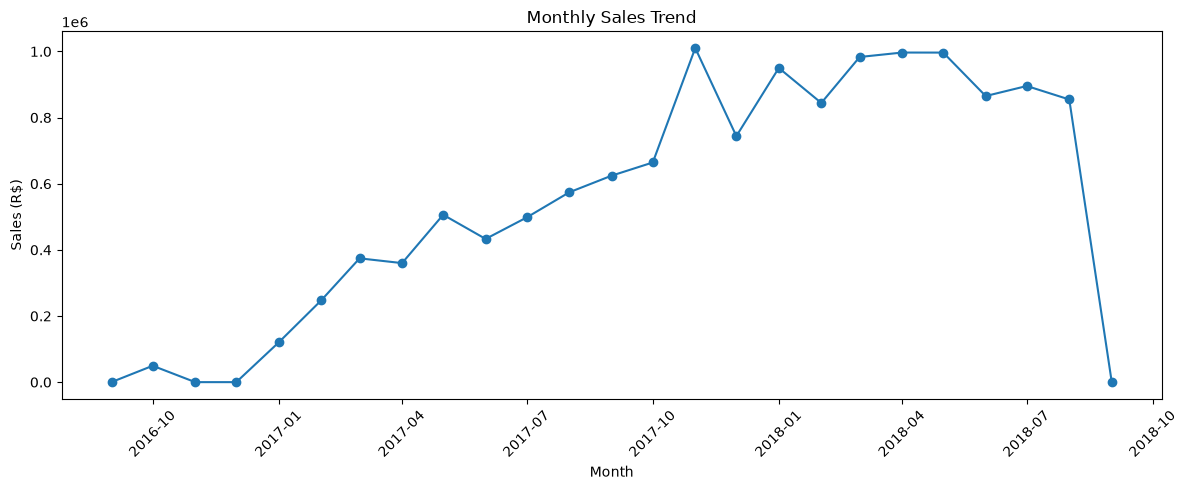

In [4]:
# Plot the monthly sales trend.

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (R$)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Monthly Sales Trend

Monthly sales were calculated using `order_purchase_timestamp` as the primary sales date and `sales` as the product-level sales measure.

The monthly trend shows strong growth in sales throughout 2017, followed by consistently high monthly sales during most of 2018. Monthly sales reached approximately 1.01 million in November 2017, with several months in 2018 also approaching 1 million.

The very low sales values at the beginning and end of the dataset should not be interpreted as a sudden change in business performance because these periods represent partial months within the available historical data.

This analysis provides an initial view of sales growth and seasonality before comparing performance across years.

## 2. Yearly Sales Trend

In [5]:
# Calculate total sales for each year.

yearly_sales = (
    retailiq
    .set_index("order_purchase_timestamp")["sales"]
    .resample("YS")
    .sum()
)

# Display yearly sales.

display(yearly_sales)

order_purchase_timestamp
2016-01-01      49785.92
2017-01-01    6155806.98
2018-01-01    7386050.80
Freq: YS-JAN, Name: sales, dtype: float64

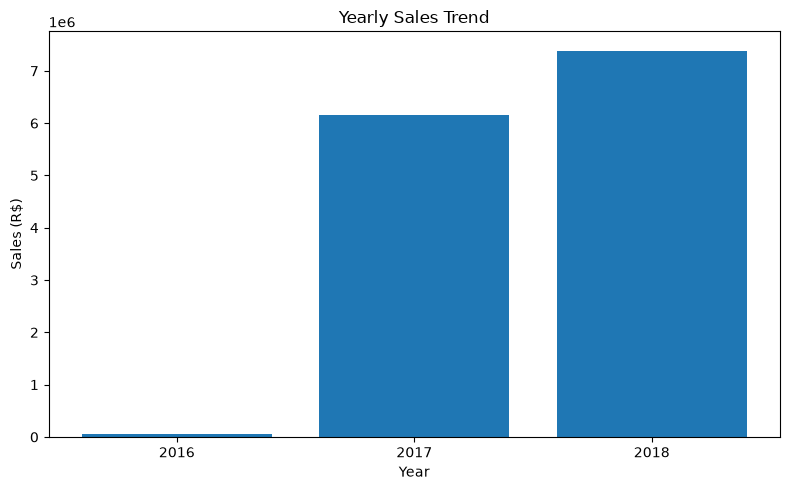

In [6]:
# Plot the yearly sales trend.

plt.figure(figsize=(8, 5))

plt.bar(
    yearly_sales.index.year.astype(str),
    yearly_sales.values
)

plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Sales (R$)")

plt.tight_layout()
plt.show()

### Yearly Sales Trend

Yearly sales show a substantial increase in the sales volume of the RetailIQ dataset over the available period.

Sales increased from approximately R$49.8K in 2016 to R$6.16M in 2017. Sales recorded for 2018 reached approximately R$7.39M, which is higher than the total for 2017.

However, 2016 and 2018 represent partial periods within the dataset. Therefore, the yearly totals should not be interpreted as direct full-year growth comparisons.

The analysis indicates strong overall growth in sales activity from 2017 onward, while the incomplete periods should be considered when performing year-over-year comparisons or forecasting.

## 3. Monthly Order Volume

In [7]:
# Calculate the number of orders placed each month.

monthly_orders = (
    retailiq
    .set_index("order_purchase_timestamp")["order_id"]
    .resample("MS")
    .nunique()
)

# Display the monthly order volume.

display(monthly_orders)

order_purchase_timestamp
2016-09-01       3
2016-10-01     308
2016-11-01       0
2016-12-01       1
2017-01-01     789
2017-02-01    1733
2017-03-01    2641
2017-04-01    2391
2017-05-01    3660
2017-06-01    3217
2017-07-01    3969
2017-08-01    4293
2017-09-01    4243
2017-10-01    4568
2017-11-01    7451
2017-12-01    5624
2018-01-01    7220
2018-02-01    6694
2018-03-01    7188
2018-04-01    6934
2018-05-01    6853
2018-06-01    6160
2018-07-01    6273
2018-08-01    6452
2018-09-01       1
Freq: MS, Name: order_id, dtype: int64

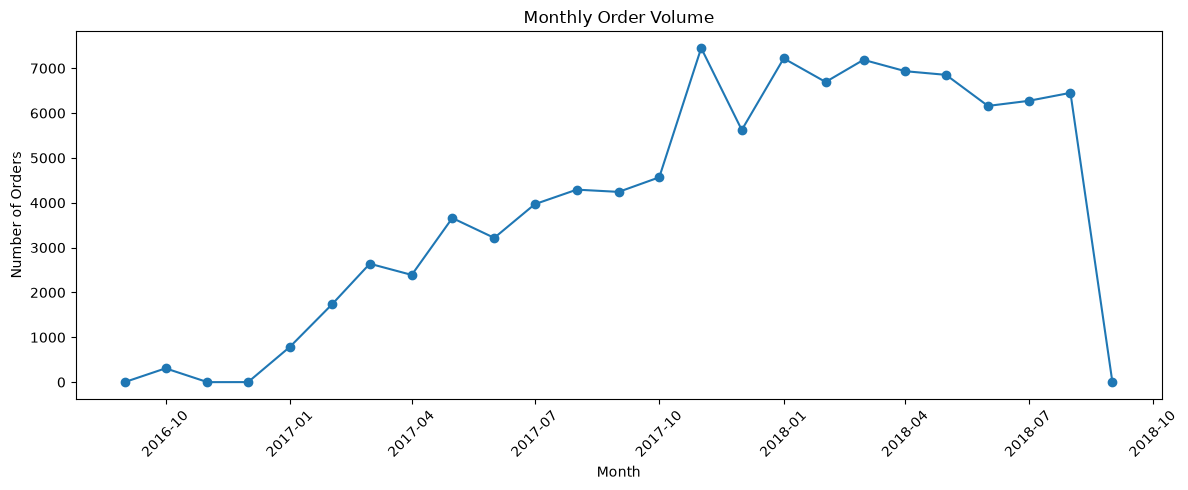

In [8]:
# Plot the monthly order volume.

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_orders.index,
    monthly_orders.values,
    marker="o"
)

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Monthly Order Volume

Monthly order volume shows a strong increase in order activity throughout 2017, followed by consistently high order volumes during most of 2018.

Order volume reached its highest point in November 2017 with 7,451 orders, which corresponds with the peak observed in monthly sales. During 2018, monthly order volume generally remained between approximately 6,100 and 7,200 orders.

The very low order count at the beginning and end of the dataset represents partial periods and should not be interpreted as a sudden change in customer demand.

The similarity between the sales and order-volume trends suggests that the growth in sales was substantially associated with an increase in the number of orders.

## 4. Average Order Value

In [9]:
# Calculate the average sales value per order for each month.
# AOV = total sales / number of unique orders.

monthly_aov = (
    monthly_sales
    / monthly_orders
)

# Display the monthly average order value.

display(monthly_aov)

order_purchase_timestamp
2016-09-01     89.120000
2016-10-01    160.739156
2016-11-01           NaN
2016-12-01     10.900000
2017-01-01    152.487795
2017-02-01    142.702262
2017-03-01    141.743393
2017-04-01    150.534182
2017-05-01    138.270803
2017-06-01    134.609450
2017-07-01    125.480343
2017-08-01    133.699436
2017-09-01    147.160427
2017-10-01    145.407056
2017-11-01    135.588695
2017-12-01    132.274924
2018-01-01    131.583152
2018-02-01    126.109756
2018-03-01    136.785398
2018-04-01    143.733451
2018-05-01    145.413349
2018-06-01    140.442258
2018-07-01    142.755814
2018-08-01    132.468433
2018-09-01    145.000000
Freq: MS, dtype: float64

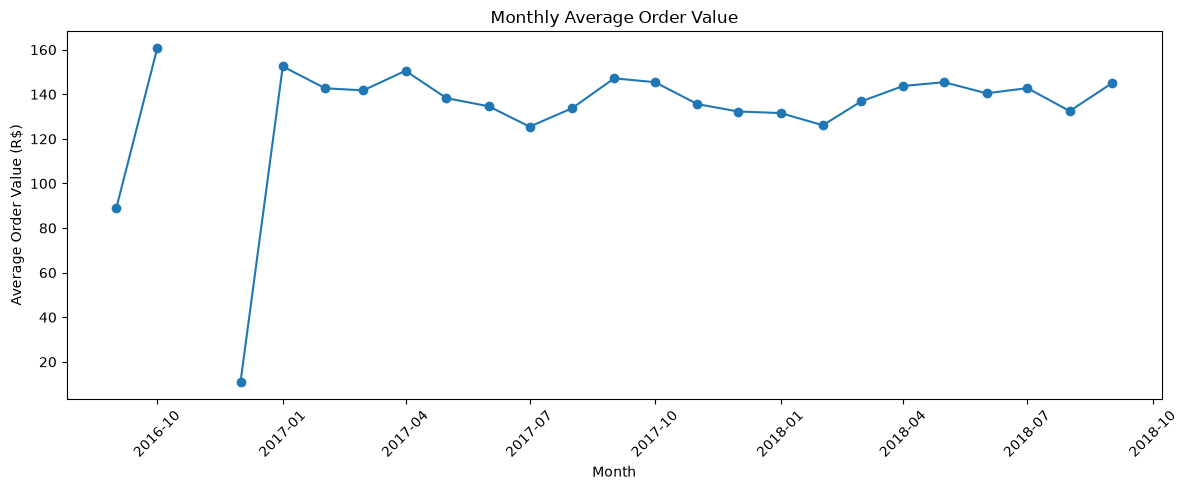

In [10]:
# Plot the monthly Average Order Value.

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_aov.index,
    monthly_aov.values,
    marker="o"
)

plt.title("Monthly Average Order Value")
plt.xlabel("Month")
plt.ylabel("Average Order Value (R$)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Monthly Average Order Value

The monthly Average Order Value (AOV) remains relatively stable throughout 2017 and 2018, generally ranging between approximately R$125 and R$150 per order.

Unlike the strong increase observed in monthly sales and order volume, AOV does not show a comparable upward trend. This suggests that the growth in total sales was primarily associated with an increase in the number of orders rather than a substantial increase in the value of individual orders.

The extreme values observed during the partial 2016 period are not representative of the later period and are therefore not used to assess the underlying AOV trend.

AOV will be used as a supporting metric when evaluating sales performance and customer purchasing behavior.

## 5. Sales by Product Category

In [11]:
# Calculate total sales for each product category.

category_sales = (
    retailiq
    .groupby("product_category_english")["sales"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 15 product categories by sales.

display(category_sales.head(15))

product_category_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
toys                      483946.60
baby                      411764.89
perfumery                 399124.87
telephony                 323667.53
office_furniture          273960.70
Name: sales, dtype: float64

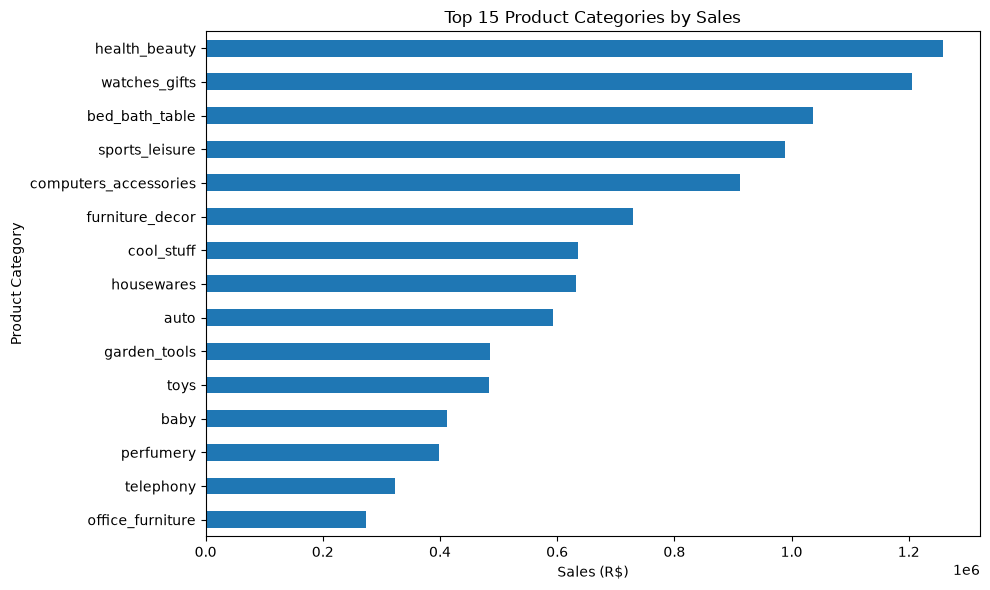

In [12]:
# Plot the top 15 product categories by sales.

plt.figure(figsize=(10, 6))

category_sales.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Product Categories by Sales")
plt.xlabel("Sales (R$)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

### Sales by Product Category

Sales were aggregated by English product category to identify the categories generating the highest sales.

Health & Beauty generated the highest sales at approximately R$1.26M, followed by Watches & Gifts at R$1.21M, and Bed, Bath & Table at R$1.04M. Sports & Leisure and Computers & Accessories were also among the strongest-performing categories.

The results show that sales are distributed across several product categories rather than being concentrated in a single category. These high-performing categories can be examined further to understand their contribution to overall sales and order volume.

## 6. Seller Sales Performance

In [13]:
# Calculate total sales generated by each seller.

seller_sales = (
    retailiq
    .groupby("seller_id")["sales"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 15 sellers by sales.

display(seller_sales.head(15))

seller_id
4869f7a5dfa277a7dca6462dcf3b52b2    229472.63
53243585a1d6dc2643021fd1853d8905    222776.05
4a3ca9315b744ce9f8e9374361493884    200472.92
fa1c13f2614d7b5c4749cbc52fecda94    194042.03
7c67e1448b00f6e969d365cea6b010ab    187923.89
7e93a43ef30c4f03f38b393420bc753a    176431.87
da8622b14eb17ae2831f4ac5b9dab84a    160236.57
7a67c85e85bb2ce8582c35f2203ad736    141745.53
1025f0e2d44d7041d6cf58b6550e0bfa    138968.55
955fee9216a65b617aa5c0531780ce60    135171.70
46dc3b2cc0980fb8ec44634e21d2718e    128111.19
6560211a19b47992c3666cc44a7e94c0    123304.83
620c87c171fb2a6dd6e8bb4dec959fc6    114774.50
7d13fca15225358621be4086e1eb0964    113628.97
5dceca129747e92ff8ef7a997dc4f8ca    112155.53
Name: sales, dtype: float64

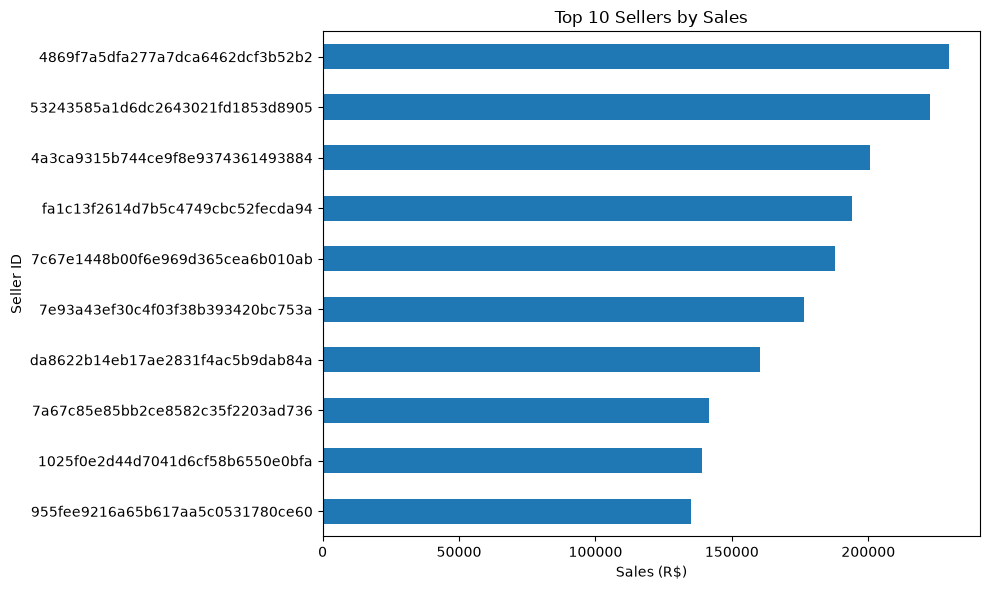

In [14]:
# Select the top 10 sellers by total sales.

top_sellers = seller_sales.head(10).sort_values()

# Plot seller sales.

plt.figure(figsize=(10, 6))

top_sellers.plot(kind="barh")

plt.title("Top 10 Sellers by Sales")
plt.xlabel("Sales (R$)")
plt.ylabel("Seller ID")

plt.tight_layout()
plt.show()

In [15]:
# Check the seller location fields available in the analytical dataset.

display(
    retailiq[
        ["seller_id", "seller_city", "seller_state"]
    ].drop_duplicates("seller_id").head(10)
)

,seller_id,seller_city,seller_state
0,48436dade18ac8b2bce089ec2a041202,volta redonda,SP
1,dd7ddc04e1b6c2c614352b383efe2d36,sao paulo,SP
2,5b51032eddd242adc84c38acab88f23d,borda da mata,MG
3,9d7a1d34a5052409006425275ba1c2b4,franca,SP
4,df560393f3a51e74553ab94004ba5c87,loanda,PR
5,6426d21aca402a131fc0a5d0960a3c90,ribeirao preto,SP
6,7040e82f899a04d1b434b795a43b4617,sao paulo,SP
7,5996cddab893a4652a15592fb58ab8db,presidente prudente,SP
8,a416b6a846a11724393025641d4edd5e,sao paulo,SP
9,ba143b05f0110f0dc71ad71b4466ce92,sao paulo,SP


In [16]:
# Create a lookup table containing seller location information.

seller_info = (
    retailiq[
        ["seller_id", "seller_city", "seller_state"]
    ]
    .drop_duplicates("seller_id")
)

# Add seller location to the top-selling sellers.

top_sellers_location = (
    seller_sales.head(10)
    .reset_index()
    .merge(seller_info, on="seller_id", how="left")
)

# Create a readable label for each seller.

top_sellers_location["seller_label"] = (
    "Seller "
    + (top_sellers_location.index + 1).astype(str)
    + " - "
    + top_sellers_location["seller_city"].str.title()
    + ", "
    + top_sellers_location["seller_state"].str.upper()
)

display(
    top_sellers_location[
        ["seller_label", "seller_id", "sales"]
    ]
)

,seller_label,seller_id,sales
0,"Seller 1 - Guariba, SP",4869f7a5dfa277a7dca6462dcf3b52b2,229472.63
1,"Seller 2 - Lauro De Freitas, BA",53243585a1d6dc2643021fd1853d8905,222776.05
2,"Seller 3 - Ibitinga, SP",4a3ca9315b744ce9f8e9374361493884,200472.92
3,"Seller 4 - Sumare, SP",fa1c13f2614d7b5c4749cbc52fecda94,194042.03
4,"Seller 5 - Itaquaquecetuba, SP",7c67e1448b00f6e969d365cea6b010ab,187923.89
5,"Seller 6 - Barueri, SP",7e93a43ef30c4f03f38b393420bc753a,176431.87
6,"Seller 7 - Piracicaba, SP",da8622b14eb17ae2831f4ac5b9dab84a,160236.57
7,"Seller 8 - Sao Paulo, SP",7a67c85e85bb2ce8582c35f2203ad736,141745.53
8,"Seller 9 - Sao Paulo, SP",1025f0e2d44d7041d6cf58b6550e0bfa,138968.55
9,"Seller 10 - Sao Paulo, SP",955fee9216a65b617aa5c0531780ce60,135171.70


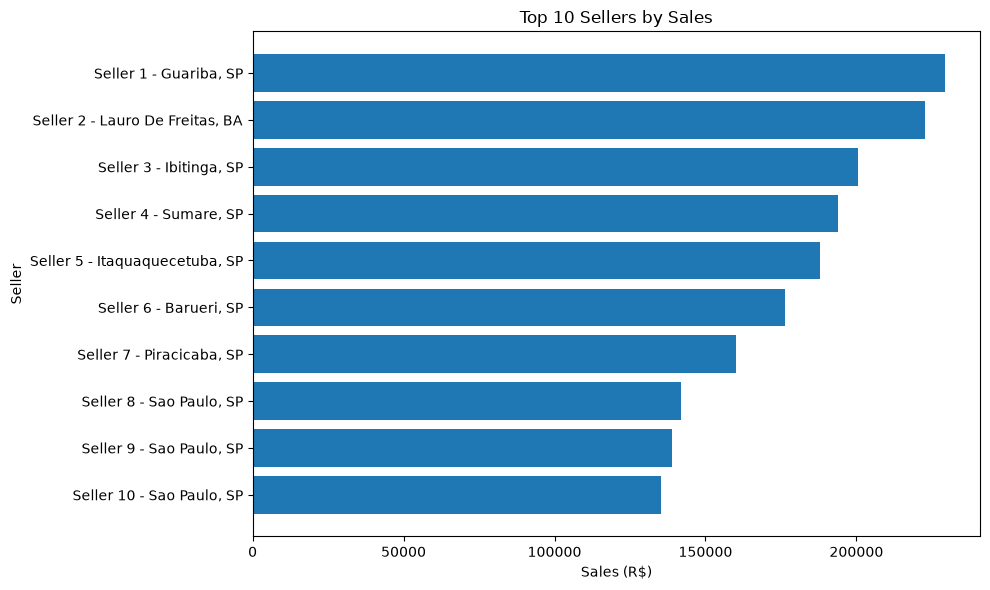

In [17]:
# Sort sellers so the highest-performing seller appears at the top.

chart_data = (
    top_sellers_location
    .sort_values("sales")
)

plt.figure(figsize=(10, 6))

plt.barh(
    chart_data["seller_label"],
    chart_data["sales"]
)

plt.title("Top 10 Sellers by Sales")
plt.xlabel("Sales (R$)")
plt.ylabel("Seller")

plt.tight_layout()
plt.show()

### Seller Sales Performance

Sales were aggregated by seller to identify the highest-performing sellers.

The top seller generated approximately <mark>R$229.47K</mark> in sales, followed by sellers generating <mark>R$222.78K</mark> and <mark>R$200.47K</mark>.

The top 10 sellers show relatively similar sales levels, with no single seller overwhelmingly dominating the group. This suggests that sales among the highest-performing sellers are reasonably distributed.

Seller locations were included in the visualization to make the results easier to interpret while retaining the seller IDs in the underlying dataset for identification.

## 7. Payment Method Distribution

In [18]:
# Count orders by their primary payment type.

payment_type_counts = (
    retailiq["primary_payment_type"]
    .value_counts()
)

# Display the payment method distribution.

display(payment_type_counts)

primary_payment_type
credit_card    85194
boleto         22867
voucher         2897
debit_card      1689
Name: count, dtype: int64

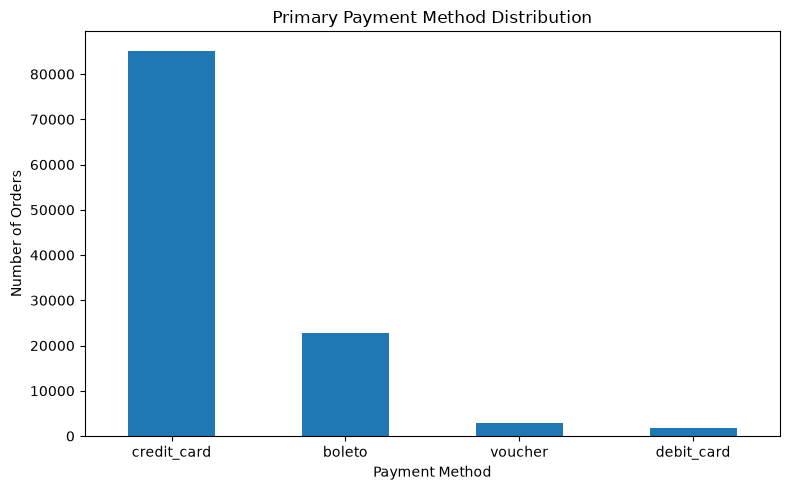

In [19]:
# Plot the distribution of primary payment methods.

plt.figure(figsize=(8, 5))

payment_type_counts.plot(kind="bar")

plt.title("Primary Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Payment Method Distribution
Payment methods were analyzed using the primary payment type associated with each order.

<mark>Credit card</mark> was the dominant payment method, accounting for approximately <mark>75.6%</mark> of orders with a recorded payment type. Boleto was the second most common method at approximately <mark>20.3%</mark>.

Voucher and debit card were used much less frequently, representing approximately <mark>2.6%</mark> and <mark>1.5%</mark> of orders respectively.

The results show that customer payments are strongly concentrated in credit card and boleto transactions, while the remaining payment methods account for a relatively small share of orders.

## 8. Payment Value by Payment Method

In [20]:
# Calculate total payment value for each primary payment method.

payment_value_by_method = (
    retailiq
    .groupby("primary_payment_type")["total_payment_value"]
    .sum()
    .sort_values(ascending=False)
)

# Display the total payment value by payment method.

display(payment_value_by_method)

primary_payment_type
credit_card    15608863.95
boleto          4059699.60
voucher          386087.30
debit_card       253483.86
Name: total_payment_value, dtype: float64

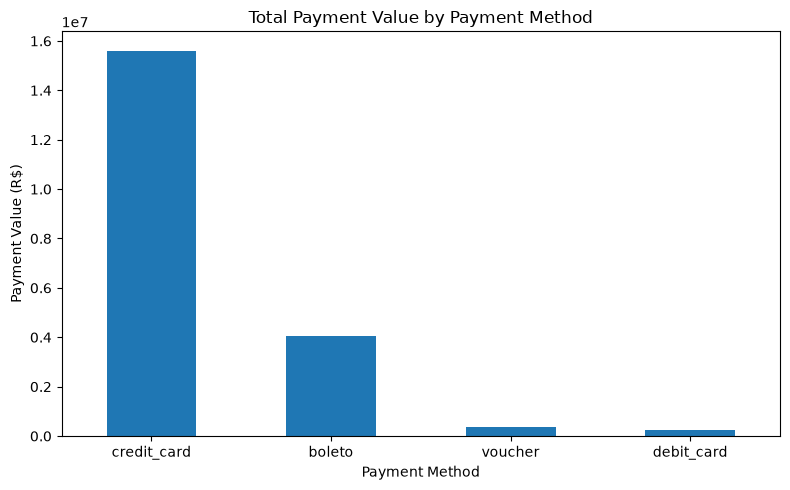

In [21]:
# Visualize total payment value by payment method.

plt.figure(figsize=(8, 5))

payment_value_by_method.plot(kind="bar")

plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Payment Value (R$)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Payment Value by Payment Method

Payment value was aggregated by primary payment method to understand the monetary contribution of each payment method.

Credit card accounts for the largest share of total payment value, consistent with its position as the most frequently used payment method. Boleto represents the second-largest payment value, while voucher and debit card contribute substantially less.

The results indicate that credit card payments are particularly important to the overall transaction value of RetailIQ. This payment distribution can later be used to understand customer payment preferences and their relationship with sales value.

## 9. Sales by Customer State

In [22]:
# Load the original customer dataset.
# We need customer location information for geographic analysis.

customers = pd.read_csv(
    "../data/raw/olist_customers_dataset.csv"
)

# Keep only the columns required for this analysis.

customer_location = customers[
    ["customer_id", "customer_city", "customer_state"]
].drop_duplicates("customer_id")

In [23]:
# Add customer location information to the RetailIQ dataset
# using customer_id as the connection between the two tables.

retailiq_geo = retailiq.merge(
    customer_location,
    on="customer_id",
    how="left"
)

# Verify that customer state was added successfully.

print(
    "Missing customer states:",
    retailiq_geo["customer_state"].isna().sum()
)

Missing customer states: 0


In [24]:
# Calculate total sales by customer state.

sales_by_customer_state = (
    retailiq_geo
    .groupby("customer_state")["sales"]
    .sum()
    .sort_values(ascending=False)
)

# Display sales by customer state.

display(sales_by_customer_state)

customer_state
SP    5202955.05
RJ    1824092.67
MG    1585308.03
RS     750304.02
PR     683083.76
SC     520553.34
BA     511349.99
DF     302603.94
GO     294591.95
ES     275037.31
PE     262788.03
CE     227254.71
PA     178947.81
MT     156453.53
MA     119648.22
MS     116812.64
PB     115268.08
PI      86914.08
RN      83034.98
AL      80314.81
SE      58920.85
TO      49621.74
RO      46140.64
AM      22356.84
AC      15982.95
AP      13474.30
RR       7829.43
Name: sales, dtype: float64

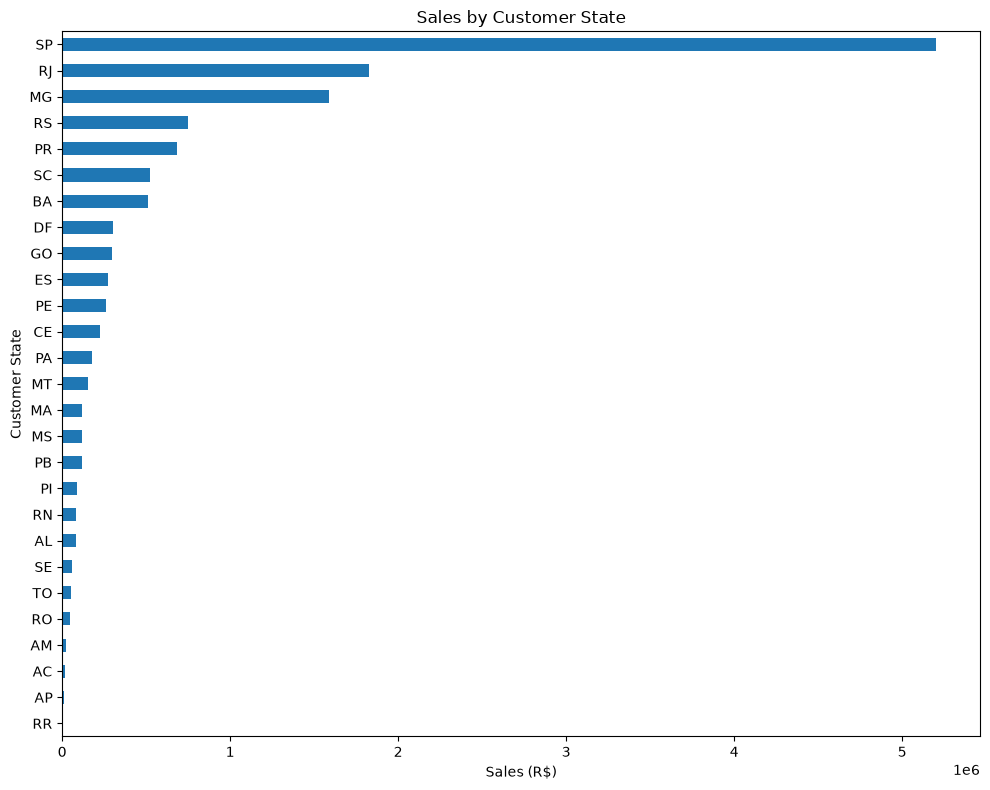

In [25]:
# Plot total sales by customer state.

plt.figure(figsize=(10, 8))

sales_by_customer_state.sort_values().plot(
    kind="barh"
)

plt.title("Sales by Customer State")
plt.xlabel("Sales (R$)")
plt.ylabel("Customer State")

plt.tight_layout()
plt.show()

### Sales by Customer State

Sales were aggregated by customer state to understand the geographic distribution of sales across Brazil.

<mark>São Paulo (SP) generated the highest sales at approximately R$5.20M</mark>, followed by Rio de Janeiro (RJ) at R$1.82M and Minas Gerais (MG) at R$1.59M.

There is a noticeable gap between these three leading states and the remaining regions. Rio Grande do Sul (RS) generated approximately R$750K, followed by Paraná (PR) at R$683K and Santa Catarina (SC) at R$521K.

The results indicate that sales are strongly concentrated in a small number of states, particularly in the Southeast region. This geographic concentration can be examined further when evaluating customer distribution, order volume, and delivery performance.

## 10. Delivery Status Distribution

In [27]:
# Calculate the number of orders by delivery status.

delivery_status_counts = (
    retailiq["delivery_status"]
    .value_counts()
)

# Display the delivery status distribution.

display(delivery_status_counts)

delivery_status
Early            101481
Delayed            8715
Not Delivered      2454
Name: count, dtype: int64

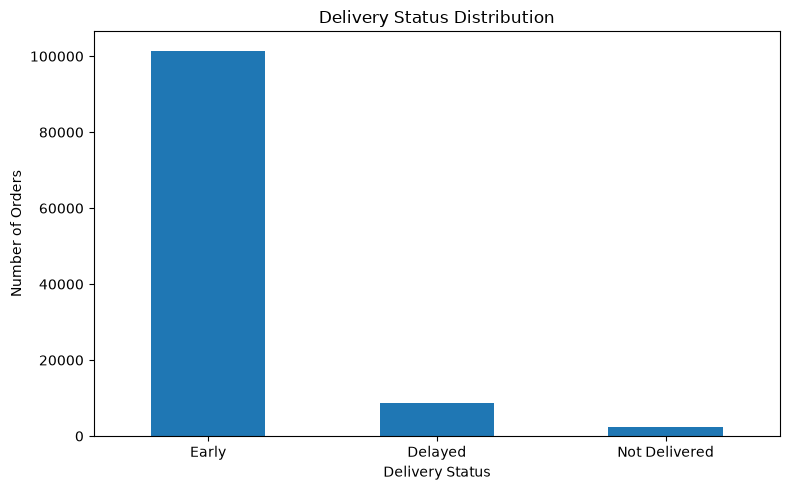

In [28]:
# Visualize the distribution of delivery statuses.

plt.figure(figsize=(8, 5))

delivery_status_counts.plot(kind="bar")

plt.title("Delivery Status Distribution")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Delivery Status Distribution

Delivery status was analyzed to understand how orders performed relative to their estimated delivery dates.

<mark>101,481 order items were classified as Early</mark>, while 8,715 were classified as Delayed. A further 2,454 records were classified as Not Delivered because the required customer delivery date was unavailable.

The results show that the majority of order items in the analytical dataset were delivered earlier than the estimated delivery date, while a much smaller proportion experienced delays.

The Not Delivered category should be interpreted carefully because it includes records where a customer delivery date was not available, rather than necessarily indicating a failed delivery.

## 11. Delivery Time Analysis

In [29]:
# Calculate summary statistics for actual delivery time.

delivery_time_summary = retailiq["delivery_days"].describe()

# Display the delivery time statistics.

display(delivery_time_summary)

count    110196.000000
mean         12.472631
std           9.445655
min           0.533414
25%           6.736262
50%          10.184282
75%          15.541097
max         209.628611
Name: delivery_days, dtype: float64

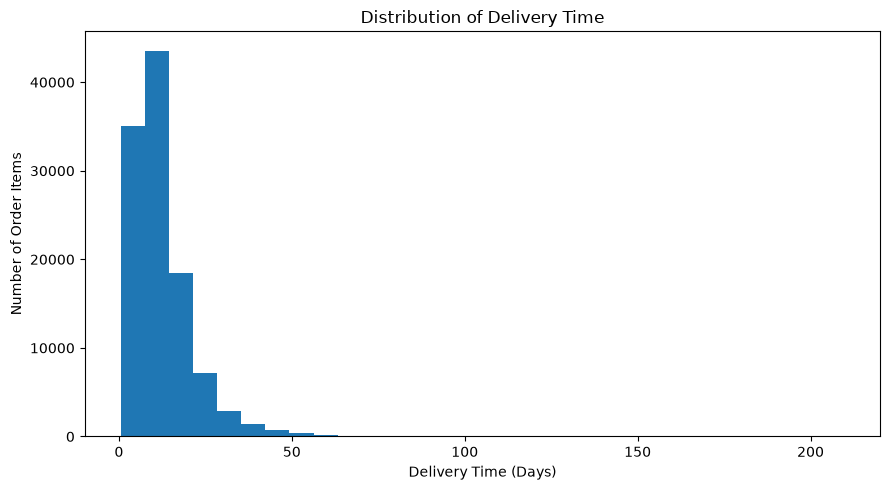

In [30]:
# Visualize the distribution of actual delivery time.

plt.figure(figsize=(9, 5))

retailiq["delivery_days"].dropna().plot(
    kind="hist",
    bins=30
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Order Items")

plt.tight_layout()
plt.show()

### Delivery Time Analysis

Actual delivery time was analyzed using the `delivery_days` field, calculated from the order purchase timestamp to the customer delivery timestamp.

<mark>The average delivery time was approximately 12.47 days, while the median delivery time was approximately 10.18 days.</mark> The middle 50% of deliveries were completed between approximately 6.74 and 15.54 days.

The distribution is strongly right-skewed, with most deliveries completed within the lower range and a smaller number of orders taking substantially longer. The maximum recorded delivery time was approximately 209.63 days.

The difference between the mean and median, together with the long right tail in the distribution, indicates that a relatively small number of unusually long deliveries increase the overall average.

These unusually long delivery times may require further investigation when analyzing delivery performance and potential operational issues.

## 12. Delivery Delay Analysis

In [31]:
# Calculate summary statistics for delivery delay.

delivery_delay_summary = retailiq["delivery_delay_days"].describe()

# Display the delivery delay statistics.

display(delivery_delay_summary)

count    110196.000000
mean        -11.333149
std          10.162342
min        -146.016123
25%         -16.321042
50%         -12.046788
75%          -6.476803
max         188.975081
Name: delivery_delay_days, dtype: float64

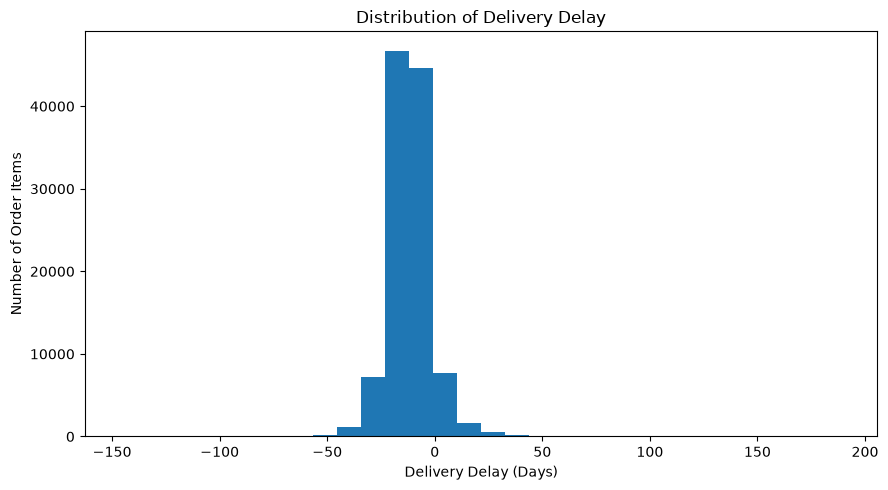

In [34]:
# Visualize the distribution of delivery delay.

plt.figure(figsize=(9, 5))

retailiq["delivery_delay_days"].dropna().plot(
    kind="hist",
    bins=30
)

plt.title("Distribution of Delivery Delay")
plt.xlabel("Delivery Delay (Days)")
plt.ylabel("Number of Order Items")

plt.tight_layout()
plt.show()

### Delivery Delay Analysis

Delivery delay was analyzed using the `delivery_delay_days` field, where negative values indicate delivery before the estimated date and positive values indicate delivery after the estimated date.

<mark>The average delivery delay was approximately -11.33 days, while the median was approximately -12.05 days.</mark> This indicates that deliveries in the analytical dataset were typically completed ahead of the estimated delivery date.

The middle 50% of records had delivery delays between approximately -16.32 and -6.48 days, meaning that most deliveries were completed several days before the estimated date.

The distribution is concentrated on the negative side, which is consistent with the earlier finding that most records were classified as Early. A small number of records show very large negative or positive deviations from the estimated date, creating long tails in the distribution.

These extreme values should be retained for now and may be investigated separately as potential operational or data-quality outliers.

## 13. Review Score Distribution

In [35]:
# Calculate the number of reviews for each review score.

review_score_counts = (
    retailiq["review_score"]
    .value_counts()
    .sort_index()
)

# Display the review score distribution.

display(review_score_counts)

review_score
1.000000    14079
1.500000       18
2.000000     3833
2.500000       45
3.000000     9384
3.333333        1
3.500000       31
4.000000    21166
4.333333        1
4.500000       68
5.000000    63082
Name: count, dtype: int64

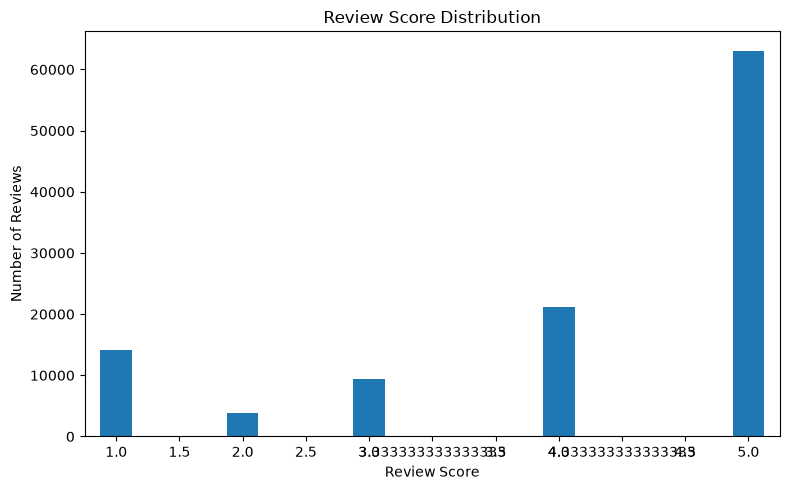

In [36]:
# Visualize the distribution of review scores.

plt.figure(figsize=(8, 5))

review_score_counts.plot(kind="bar")

plt.title("Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Review Score Distribution

Review scores were analyzed to understand customer satisfaction across the order-item dataset.

<mark>5-star reviews were the most common, with 63,082 records, followed by 4-star reviews with 21,166 records.</mark> Lower ratings were less frequent overall, although 1-star reviews accounted for 14,079 records and represent a notable group of dissatisfied customers.

The distribution is therefore concentrated toward higher review scores, suggesting generally positive customer feedback in the available review data. However, the presence of a substantial number of 1-star reviews indicates that there is still a meaningful group of customers experiencing dissatisfaction.

Some fractional review scores are present because review scores were aggregated at the order level before being incorporated into the analytical dataset.

The analysis uses order-item records, so the counts should not be interpreted as unique customer or review counts.

## 14. Sales vs Review Score

In [38]:
# Calculate average sales for each review score.

sales_by_review_score = (
    retailiq
    .groupby("review_score")["sales"]
    .mean()
    .sort_index()
)

# Display the average sales by review score.

display(sales_by_review_score)

review_score
1.000000    127.823747
1.500000     73.837778
2.000000    116.361753
2.500000     79.075556
3.000000    109.942186
3.333333     26.000000
3.500000     98.637419
4.000000    118.837040
4.333333     34.990000
4.500000     78.283088
5.000000    121.444598
Name: sales, dtype: float64

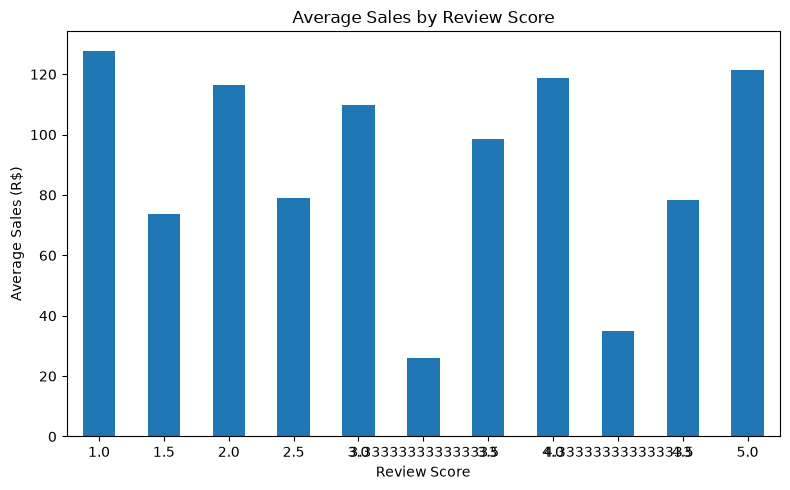

In [39]:
# Visualize the relationship between review score and average sales.

plt.figure(figsize=(8, 5))

sales_by_review_score.plot(
    kind="bar"
)

plt.title("Average Sales by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Average Sales (R$)")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Sales vs Review Score

Average sales value was compared across review scores to investigate whether higher-value purchases were associated with different customer ratings.

<mark>The results do not show a clear linear relationship between sales value and review score.</mark> Average sales was approximately R$127.82 for 1-star reviews, R$109.94 for 3-star reviews, R$118.84 for 4-star reviews, and R$121.44 for 5-star reviews.

The average sales value therefore varies across review scores without following a consistent upward or downward pattern. This suggests that order-item sales value alone does not provide a strong indication of customer satisfaction.

The fractional review scores have very few observations and should not be used for meaningful comparisons.

This analysis is exploratory and shows association rather than causation. Other factors, such as delivery performance, product category, and seller performance, may have a stronger relationship with customer review scores.